In [ ]:
# 1. Settings
LOG_DIR = "logs"      # folder with the DNS log CSVs to analyze (Kibana exports with ECS field names); every *.csv in it is loaded
DEDUPLICATE = True    # True = drop rows whose fields all match an earlier row, within a file or across overlapping exports

### DNS Log Anomaly Detection 
Part of the DUNE project for ML-enhanced threat hunting [https://github.com/opendr-io/dune]

Ingests DNS events from an Elasticsearch export and runs a DBSCAN model to find anomalous activity in DNS logs. The last cell can be used to identify the caller by source IP if the query came from a local endpoint. 

In [ ]:
import ipaddress
import ipywidgets as widgets
from IPython.display import display
import ipywidgets as widgets
from IPython.display import display
from collections import Counter
import pandas as pd
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import proj3d
import textwrap
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

In [ ]:
#2. Ingest

# Columns the later cells use
REQUIRED = ['@timestamp', 'source.ip', 'destination.ip', 'dns.question.name',
            'dns.answers.name', 'dns.type', 'dns.question.type']

frames = []
for path in sorted(Path(LOG_DIR).glob("*.csv")):
    log = pd.read_csv(path)
    missing = [col for col in REQUIRED if col not in log.columns]
    if missing:
        print(f"Skipping {path.name}: missing columns {missing}")
        continue
    frames.append(log.assign(log_file=path.name))
if not frames:
    raise FileNotFoundError(f"No usable DNS log CSVs in {Path(LOG_DIR).resolve()}")

df = pd.concat(frames, ignore_index=True)
# Kibana writes '-' for empty fields; treat blank cells the same way
df[REQUIRED] = df[REQUIRED].fillna('-')

# Drop rows whose fields all match an earlier row (log_file isn't compared, so the first file's copy is kept)
if DEDUPLICATE:
    before = len(df)
    df = df.drop_duplicates(subset=df.columns.drop('log_file'), ignore_index=True)
    print(f"Dropped {before - len(df)} duplicate rows")
print(f"Loaded {len(df)} events from {len(frames)} file(s)")

In [ ]:
#3. Features

def query_length(query):
    return len(query)

def query_parts(query):
    return len(query.split('.'))

def query_suffix_length(query):
    return len(query.split('.')[-1])

def query_domain_length(query):
    try:
        length =  len(query.split('.')[-2])
    except:
        length = 0
    return length

qlengths = [query_length(query) for query in df['dns.question.name']]
qparts = [query_parts(query) for query in df['dns.question.name']]
qsufflengths = [query_suffix_length(query) for query in df['dns.question.name']]
qdomlengths = [query_domain_length(query) for query in df['dns.question.name']]

df['qlength'] = qlengths
df['qparts'] = qparts
df['suffixlength'] = qsufflengths
df['domainlength'] = qdomlengths
df['answerlength'] = df['dns.answers.name'].str.len()

In [ ]:

# 4. Additional features
# Record types that get their own 0/1 feature column; anything else (e.g. AXFR, exported as '252') goes in type_other
QTYPES = ['A', 'AAAA', 'CNAME', 'MX', 'NS', 'PTR', 'SRV', 'TXT', 'ANY']
TYPE_COLUMNS = [f'type_{t}' for t in QTYPES] + ['type_other']

def query_entropy(query):
    # Shannon entropy (bits/char) of the first label; high for random or encoded subdomains
    label = query.split('.')[0]
    if not label:
        return 0.0
    counts = Counter(label)
    n = len(label)
    return -sum(c/n * np.log2(c/n) for c in counts.values())

def query_longest_label(query):
    return max(len(part) for part in query.split('.'))

def query_inbound(source_ip):
    # 1 = sent from a public internet address (e.g. scanners), 0 = from an internal host
    try:
        return int(ipaddress.ip_address(str(source_ip).strip()).is_global)
    except ValueError:
        return 0   # missing or not an IP, e.g. '-' in Kibana exports

# One-hot record type: type numbers (A=1, ANY=255) aren't distances, so each type gets its own 0/1 column
qtypes = df['dns.question.type'].astype(str).str.upper()
for t in QTYPES:
    df[f'type_{t}'] = (qtypes == t).astype(int)
df['type_other'] = (~qtypes.isin(QTYPES)).astype(int)
df['entropy'] = [query_entropy(query) for query in df['dns.question.name']]
df['longestlabel'] = [query_longest_label(query) for query in df['dns.question.name']]
df['inbound'] = [query_inbound(ip) for ip in df['source.ip']]

In [ ]:
data = df[['qlength', 'qparts', 'suffixlength',
           'answerlength', 'domainlength',
           'entropy', 'longestlabel', 'inbound'] + TYPE_COLUMNS].to_numpy()

# 5. Create a scaled copy of the data
scaler = StandardScaler()
scaler.fit(data)
scaled = scaler.transform(data)

# Apply a PCA 3 to the scaled data
pca = PCA(3)
pca.fit(scaled)
reduced = pca.transform(scaled)

# Cluster the scaled data using the values provided in the instructions
dbscan = DBSCAN(n_jobs=-1, min_samples=5, eps=0.8)
dbscan.fit(scaled)

# Copy the labels
y_labels = dbscan.labels_
y_labels

# 7. Select clusters 
df['cluster'] = y_labels

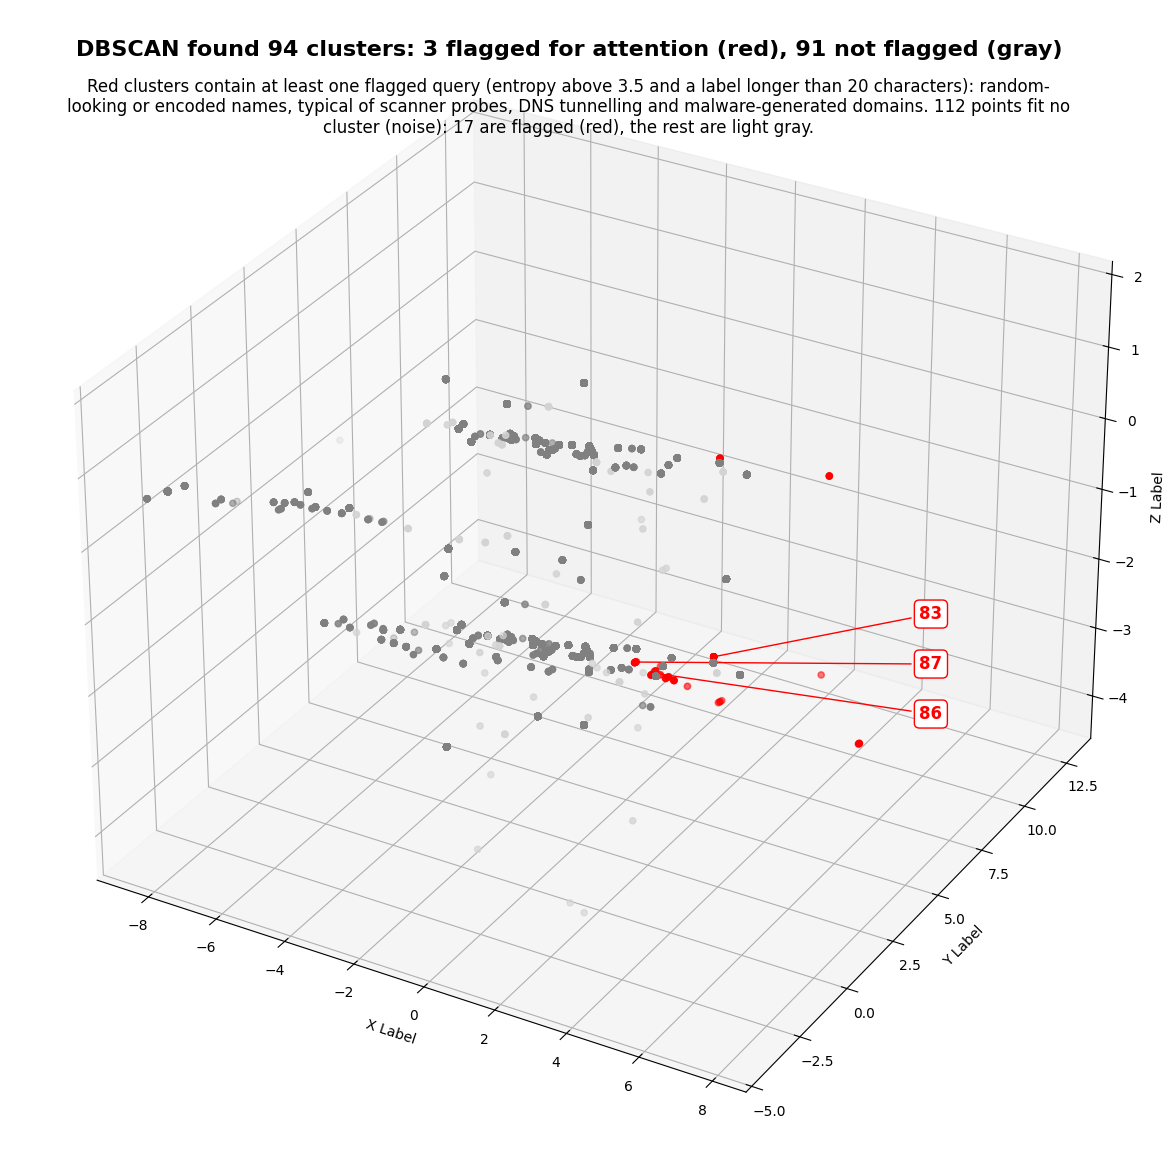

In [42]:
#6. Plot the clusters
def scatter3d(data, labels, flagged, flag_rule):
    # Red = clusters containing flagged rows and flagged noise points; other clusters gray, other noise light gray
    red_clusters = set(labels[flagged]) - {-1}
    noise = labels == -1
    fig = plt.figure()
    fig.set_figheight(15)
    fig.set_figwidth(15)
    ax = fig.add_subplot(111, projection='3d')
    # Unflagged noise first, then gray clusters, then red, so red is drawn on top
    ax.scatter(*data[noise & ~flagged, :3].T, c='lightgray')
    for cluster in sorted(set(labels) - {-1}, key=lambda c: c in red_clusters):
        points = data[labels==cluster]
        color = 'red' if cluster in red_clusters else 'gray'
        ax.scatter(points[:, 0], points[:, 1], points[:, 2], c=color)
    ax.scatter(*data[noise & flagged, :3].T, c='red')
    ax.set_xlabel('X Label')
    ax.set_ylabel('Y Label')
    ax.set_zlabel('Z Label')

    # Explain what the plot shows, with the counts for this run
    n_clusters = len(set(labels) - {-1})
    fig.suptitle(f"DBSCAN found {n_clusters} clusters: {len(red_clusters)} flagged for attention (red), "
                 f"{n_clusters - len(red_clusters)} not flagged (gray)", fontsize=16, weight='bold', y=0.86)
    caption = (f"Red clusters contain at least one flagged query ({flag_rule}): random-looking or encoded "
               f"names, typical of scanner probes, DNS tunnelling and malware-generated domains. "
               f"{noise.sum()} points fit no cluster (noise): {(noise & flagged).sum()} are flagged (red), "
               f"the rest are light gray.")
    fig.text(0.5, 0.835, textwrap.fill(caption, 120), ha='center', va='top', fontsize=12)

    # Number the clusters containing flagged rows, set off from their points with a line back to the centre
    fig.canvas.draw()  # settles the axis limits so the projected positions are final
    centres, pixels = {}, {}
    for cluster in red_clusters:
        x, y, _ = proj3d.proj_transform(*np.median(data[labels==cluster, :3], axis=0), ax.get_proj())
        centres[cluster] = (x, y)
        pixels[cluster] = ax.transData.transform((x, y))
    # Stack the labels in a column right of every red point, in the same top-to-bottom order as their
    # clusters, so the labels cover no red points and the lines back to them never cross
    order = sorted(red_clusters, key=lambda c: -pixels[c][1])
    spacing = 50
    red_x, red_y, _ = proj3d.proj_transform(*data[flagged, :3].T, ax.get_proj())
    right = ax.transData.transform(np.column_stack([red_x, red_y]))[:, 0].max() + 60
    top = np.mean([py for _, py in pixels.values()]) + spacing * (len(order) - 1) / 2
    for k, cluster in enumerate(order):
        px, py = pixels[cluster]
        offset = ((right - px) * 72 / fig.dpi, (top - k * spacing - py) * 72 / fig.dpi)  # pixels -> points
        ax.annotate(str(cluster), xy=centres[cluster], xytext=offset, textcoords='offset points',
                    fontsize=12, weight='bold', color='red', zorder=10, va='center',
                    bbox=dict(boxstyle='round', fc='white', ec='red'),
                    arrowprops=dict(arrowstyle='-', color='red'))
    plt.show()

# Flag random/encoded first labels: high entropy AND a long label
MIN_ENTROPY, MIN_LABEL = 3.5, 20
df['flagged'] = (df['entropy'] > MIN_ENTROPY) & (df['longestlabel'] > MIN_LABEL)

scatter3d(reduced, y_labels, df['flagged'].to_numpy(),
          flag_rule=f"entropy above {MIN_ENTROPY} and a label longer than {MIN_LABEL} characters")

In [ ]:
# 7. Show full query names instead of truncating them with "..."
pd.set_option('display.max_colwidth', None)

# Sort key that puts noise (-1) after the real clusters
noise_last = lambda c: c.where(c != -1, c.max() + 1)

# Public = callers on the internet (inbound = 1), Private = internal hosts (inbound = 0)
flagged_toggle = widgets.ToggleButtons(options=['All', 'Public', 'Private'], description='Source:',
                                       tooltips=['Any caller', 'Callers on the internet', 'Internal hosts'])
flagged_output = widgets.Output()

def show_flagged(_=None):
    flagged = df[df['flagged']]
    if flagged_toggle.value == 'Public':
        flagged = flagged[flagged['inbound'] == 1]
    elif flagged_toggle.value == 'Private':
        flagged = flagged[flagged['inbound'] == 0]
    with flagged_output:
        flagged_output.clear_output()
        print(f"{len(flagged)} flagged rows")
        print()
        if not len(flagged):
            return
        # Which clusters the flagged rows fall in, vs. each cluster's total size (-1 = noise, no cluster)
        summary = pd.DataFrame({
            'flagged': flagged['cluster'].value_counts(),
            'cluster_size': df['cluster'].value_counts()
        }).dropna().astype(int).sort_index(key=noise_last)
        print(summary)
        display(flagged[['@timestamp', 'source.ip',
                         'dns.question.name', 'dns.question.type', 'entropy', 'longestlabel', 'cluster']].sort_values(['entropy', 'longestlabel'], ascending=False))

flagged_toggle.observe(show_flagged, names='value')
show_flagged()
display(widgets.VBox([flagged_toggle, flagged_output]))

In [ ]:
# 8. Search DNS events by caller IP, query name and/or whether the caller is public or private
# Copy so the parsed timestamps don't change df
events = df.copy()
events['@timestamp'] = pd.to_datetime(events['@timestamp'], format='%b %d, %Y @ %H:%M:%S.%f')

def lookup(source_ip=None, query=None, source_type='All'):
    # source_ip must match exactly; query matches any part of the name, ignoring case (e.g. 'fflpz')
    # source_type: 'Public' = callers on the internet (inbound = 1), 'Private' = internal hosts (inbound = 0)
    mask = pd.Series(True, index=events.index)
    if source_type == 'Public':
        mask &= events['inbound'] == 1
    elif source_type == 'Private':
        mask &= events['inbound'] == 0
    if source_ip:
        mask &= events['source.ip'] == source_ip
    if query:
        mask &= events['dns.question.name'].str.contains(query, case=False, regex=False)
    result = events.loc[mask, ['@timestamp', 'source.ip', 'destination.ip', 'dns.type',
                               'dns.question.name', 'dns.question.type', 'entropy', 'longestlabel', 'cluster']]
    return result.sort_values('@timestamp')

# Source IP box suggests IPs from the data as you type; Enter or Search runs the lookup
ip_box = widgets.Combobox(placeholder='e.g. 165.22.213.54', description='Source IP:',
                          options=sorted(events['source.ip'].unique()), ensure_option=False,
                          continuous_update=False)
query_box = widgets.Text(placeholder='any part of the name, e.g. fflpz', description='Query:',
                         continuous_update=False)
source_toggle = widgets.ToggleButtons(options=['All', 'Public', 'Private'], description='Source:',
                                      tooltips=['Any caller', 'Callers on the internet', 'Internal hosts'])
search_button = widgets.Button(description='Search', button_style='primary', icon='search')
clear_button = widgets.Button(description='Clear')
results = widgets.Output()
clearing = False  # stops the boxes' watchers from searching while Clear empties them

def run_search(_=None):
    if clearing:
        return
    source_ip, query, source_type = ip_box.value.strip(), query_box.value.strip(), source_toggle.value
    with results:
        results.clear_output()
        if not source_ip and not query and source_type == 'All':
            print("Enter a source IP or a query, or pick Public or Private.")
            return
        found = lookup(source_ip or None, query or None, source_type)
        print(f"{len(found)} events")
        if len(found):
            display(found)

def clear_search(_=None):
    global clearing
    clearing = True
    ip_box.value = query_box.value = ''
    source_toggle.value = 'All'
    clearing = False
    results.clear_output()

search_button.on_click(run_search)
clear_button.on_click(clear_search)
ip_box.observe(run_search, names='value')
query_box.observe(run_search, names='value')
source_toggle.observe(run_search, names='value')

display(widgets.VBox([widgets.HBox([ip_box, query_box, search_button, clear_button]), source_toggle, results]))
